In [ ]:
import os
import random
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from datasets import load_dataset
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 3
MAX_CATEGORY_SAMPLES = 1200
MAX_GRADE_SAMPLES = 1200
RUN_CV = True

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

In [ ]:
CATEGORY_DATASET = "ashraq/fashion-product-images-small"

CATEGORY_MAP = {
    "shirts": "Shirt",
    "shirt": "Shirt",
    "tshirts": "T-Shirt",
    "t-shirt": "T-Shirt",
    "tshirt": "T-Shirt",
    "jeans": "Pants",
    "trousers": "Pants",
    "track pants": "Pants",
    "shorts": "Pants",
    "pants": "Pants",
    "joggers": "Pants",
    "jackets": "Jacket",
    "jacket": "Jacket"
}

def normalize_category(value):
    if value is None:
        return None
    return CATEGORY_MAP.get(str(value).strip().lower())

category_stream = load_dataset(
    CATEGORY_DATASET,
    split="train",
    streaming=True
)

category_records = []

for row in category_stream:
    category = normalize_category(row.get("articleType"))
    image = row.get("image")

    if category is None or image is None:
        continue

    try:
        category_records.append({
            "image": image.convert("RGB"),
            "label": category,
            "source": CATEGORY_DATASET,
            "item_id": str(row.get("id", ""))
        })
    except Exception:
        continue

    if len(category_records) >= MAX_CATEGORY_SAMPLES:
        break

df_category = pd.DataFrame(category_records)

print("Total:", len(df_category))
print(df_category["label"].value_counts())

if df_category.empty:
    raise ValueError("Tidak ada data kategori yang valid.")

missing_classes = set(["Shirt", "T-Shirt", "Pants", "Jacket"]) - set(
    df_category["label"]
)

if missing_classes:
    print("PERINGATAN: kategori belum ditemukan:", missing_classes)

README.md:   0%|          | 0.00/867 [00:00<?, ?B/s]

Total: 1200
label
T-Shirt    663
Shirt      317
Pants      203
Jacket      17
Name: count, dtype: int64


In [ ]:
GRADE_DATASET = "wargoninnovation/clothingdatasetsecondhand"

GRADE_MAP = {
    5: "A",
    4: "B",
    3: "C",
    2: "D",
    1: "D"
}

grade_stream = load_dataset(
    GRADE_DATASET,
    split="train",
    streaming=True
)

grade_records = []

for row in grade_stream:
    condition = row.get("condition")
    image = row.get("image")

    if condition not in GRADE_MAP or image is None:
        continue

    try:
        grade_records.append({
            "image": image.convert("RGB"),
            "label": GRADE_MAP[int(condition)],
            "condition": int(condition),
            "holes": str(row.get("holes", "")),
            "stains": str(row.get("stains", "")),
            "pilling": row.get("pilling"),
            "source": GRADE_DATASET,
            "item_id": str(row.get("filename", ""))
        })
    except Exception:
        continue

    if len(grade_records) >= MAX_GRADE_SAMPLES:
        break

df_grade = pd.DataFrame(grade_records)

print("Total:", len(df_grade))
print(df_grade["label"].value_counts().sort_index())

if df_grade.empty:
    raise ValueError("Tidak ada data grading yang valid.")

README.md:   0%|          | 0.00/15.0k [00:00<?, ?B/s]

Total: 1200
label
A    311
B    184
C    414
D    291
Name: count, dtype: int64


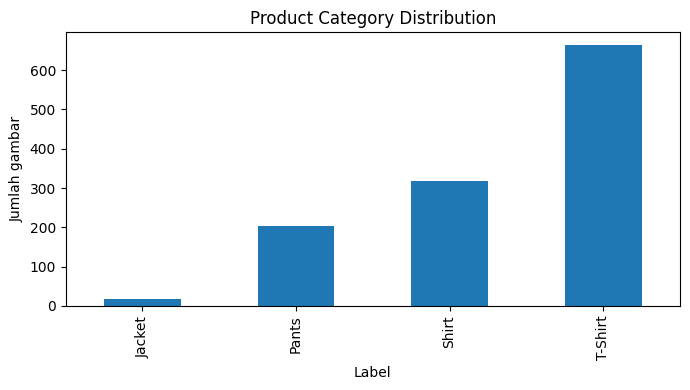

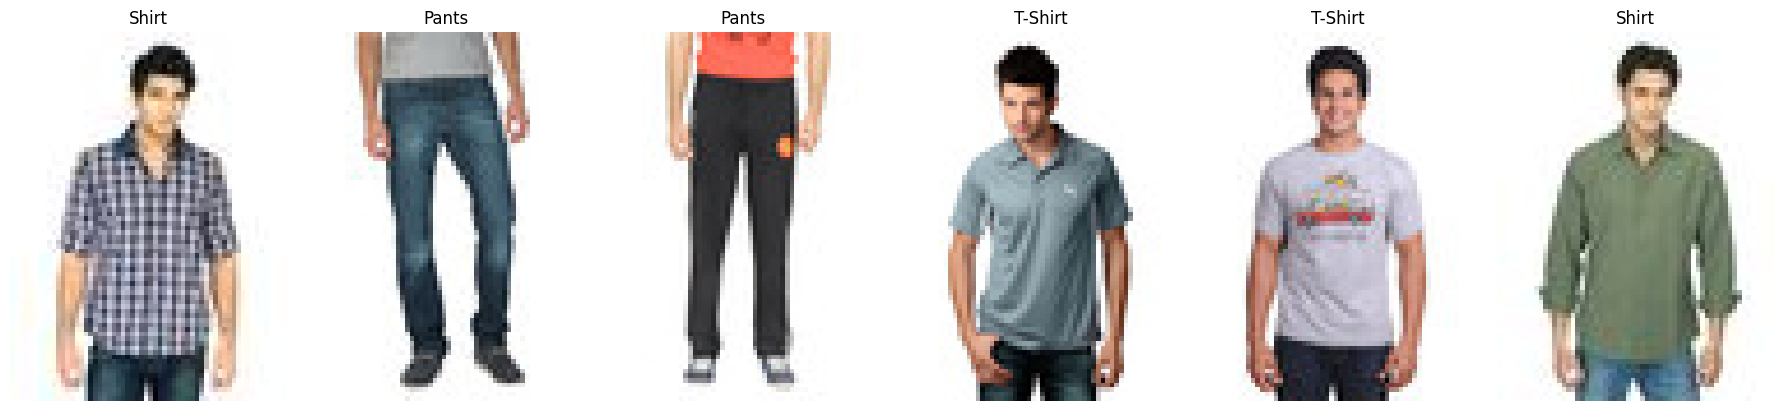

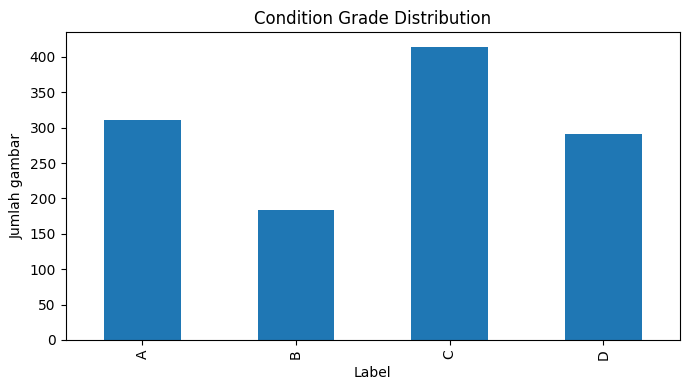

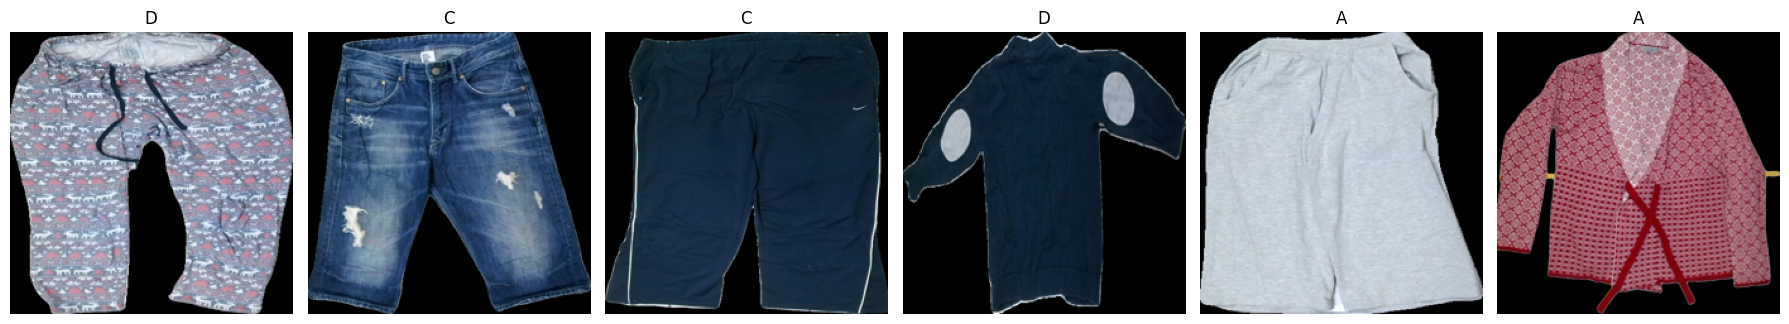

In [ ]:
def plot_distribution(df, title):
    counts = df["label"].value_counts().sort_index()
    counts.plot(kind="bar", figsize=(7, 4))
    plt.title(title)
    plt.xlabel("Label")
    plt.ylabel("Jumlah gambar")
    plt.tight_layout()
    plt.show()

def show_samples(df, n=6):
    n = min(n, len(df))
    fig, axes = plt.subplots(1, n, figsize=(3*n, 4))
    axes = np.atleast_1d(axes)

    for ax, (_, row) in zip(axes, df.head(n).iterrows()):
        ax.imshow(row["image"])
        ax.set_title(str(row["label"]))
        ax.axis("off")

    plt.tight_layout()
    plt.show()

plot_distribution(df_category, "Product Category Distribution")
show_samples(df_category)

plot_distribution(df_grade, "Condition Grade Distribution")
show_samples(df_grade)

In [ ]:
EXTRA_HF = {
    "holes": "wargoninnovation/Garment_condition_holes",
    "spots": "wargoninnovation/Garment_condition_spots"
}

extra_metadata = []

for name, dataset_id in EXTRA_HF.items():
    print("\nMemeriksa:", name)

    try:
        stream = load_dataset(
            dataset_id,
            split="train",
            streaming=True
        )

        sample = next(iter(stream))

        print("Kolom:", list(sample.keys()))

        extra_metadata.append({
            "dataset": name,
            "dataset_id": dataset_id,
            "columns": ", ".join(sample.keys()),
            "loaded": True
        })

        for key, value in sample.items():
            if key != "image":
                print(key, "=", value)

        if sample.get("image") is not None:
            display(sample["image"])

    except Exception as e:
        print("Gagal:", repr(e))
        extra_metadata.append({
            "dataset": name,
            "dataset_id": dataset_id,
            "columns": "",
            "loaded": False
        })

pd.DataFrame(extra_metadata).to_csv(
    "thrifty_extra_dataset_inventory.csv",
    index=False
)


Memeriksa: holes


README.md:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/1394 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/128 [00:00<?, ?it/s]

Kolom: ['text']
text = 0 0.465625 0.32265625 0.00546875 0.00234375

Memeriksa: spots


README.md:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/1660 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/152 [00:00<?, ?it/s]

Kolom: ['text']
text = 0 0.5208333333333334 0.6167864583333333 0.017861111111111078 0.007005208333333238


In [ ]:
import subprocess

def clone_repo(url, folder):
    if os.path.exists(folder):
        print("Folder tersedia:", folder)
        return

    result = subprocess.run(
        ["git", "clone", "--depth", "1", url, folder],
        capture_output=True,
        text=True
    )

    print("Repository:", folder)
    print("Berhasil" if result.returncode == 0 else result.stderr[:1000])

clone_repo(
    "https://github.com/PerceptiLabs/fabric_stain.git",
    "fabric_stain"
)

clone_repo(
    "https://github.com/niamul-anto/Fabric-Defect-Detection.git",
    "Fabric-Defect-Detection"
)

Repository: fabric_stain
Berhasil
Repository: Fabric-Defect-Detection
Berhasil


Preprocessing

In [ ]:
def image_to_array(image):
    image = image.convert("RGB").resize(IMG_SIZE)
    return np.asarray(image, dtype=np.uint8)

def prepare_arrays(df, classes):
    class_to_id = {name: i for i, name in enumerate(classes)}

    X = np.stack([
        image_to_array(image)
        for image in df["image"]
    ])

    y = np.asarray([
        class_to_id[label]
        for label in df["label"]
    ], dtype=np.int32)

    return X, y

CATEGORY_CLASSES = ["Shirt", "T-Shirt", "Pants", "Jacket"]
GRADE_CLASSES = ["A", "B", "C", "D"]

def validate_classes(y, classes, task_name):
    counts = pd.Series(y).value_counts().reindex(
        range(len(classes)), fill_value=0
    )

    print(task_name, "class counts:")
    print(counts)

    if (counts < 5).any():
        raise ValueError(
            f"{task_name}: ada kelas dengan kurang dari 5 sampel. "
            "Tambah data sebelum split atau 5-fold CV."
        )

X_category, y_category = prepare_arrays(
    df_category, CATEGORY_CLASSES
)

X_grade, y_grade = prepare_arrays(
    df_grade, GRADE_CLASSES
)

validate_classes(y_category, CATEGORY_CLASSES, "Category")
validate_classes(y_grade, GRADE_CLASSES, "Grading")

print("Category:", X_category.shape, y_category.shape)
print("Grading:", X_grade.shape, y_grade.shape)

Category class counts:
0    317
1    663
2    203
3     17
Name: count, dtype: int64
Grading class counts:
0    311
1    184
2    414
3    291
Name: count, dtype: int64
Category: (1200, 224, 224, 3) (1200,)
Grading: (1200, 224, 224, 3) (1200,)


Model

In [ ]:
def build_simple_cnn(num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(224, 224, 3)),
        tf.keras.layers.Rescaling(1./255),

        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(128, 3, activation="relu"),
        tf.keras.layers.GlobalAveragePooling2D(),

        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def build_mobilenet(num_classes):
    base = tf.keras.applications.MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )
    base.trainable = False

    inputs = tf.keras.Input(shape=(224, 224, 3))

    x = tf.keras.layers.Rescaling(
        scale=1./127.5,
        offset=-1.0
    )(inputs)

    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(
        num_classes, activation="softmax"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

MODEL_BUILDERS = {
    "Simple CNN": build_simple_cnn,
    "MobileNetV2": build_mobilenet
}

In [ ]:
def make_tf_dataset(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))

    if training:
        ds = ds.shuffle(
            min(len(X), 2000),
            seed=SEED
        )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def run_experiment(
    task_name, model_name, split_name,
    X_train, y_train, X_test, y_test,
    class_names, validation_data=None
):
    tf.keras.backend.clear_session()
    model = MODEL_BUILDERS[model_name](len(class_names))

    train_ds = make_tf_dataset(X_train, y_train, training=True)
    test_ds = make_tf_dataset(X_test, y_test)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss" if validation_data else "loss",
            patience=2,
            restore_best_weights=True
        )
    ]

    fit_args = {
        "x": train_ds,
        "epochs": EPOCHS,
        "callbacks": callbacks,
        "verbose": 1
    }

    if validation_data:
        fit_args["validation_data"] = make_tf_dataset(
            validation_data[0], validation_data[1]
        )

    history = model.fit(**fit_args)

    probs = model.predict(test_ds, verbose=0)
    pred = np.argmax(probs, axis=1)

    result = {
        "Task": task_name,
        "Model": model_name,
        "Split": split_name,
        "Train": len(y_train),
        "Test": len(y_test),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_test, pred, average="macro", zero_division=0
        )
    }

    return result, model, pred, history

ex 70,80,90

In [ ]:
SPLITS = {
    "70:30": 0.30,
    "80:20": 0.20,
    "90:10": 0.10
}

TASKS = {
    "Category": (X_category, y_category, CATEGORY_CLASSES),
    "Grading": (X_grade, y_grade, GRADE_CLASSES)
}

split_results = []
saved_models = {}
saved_predictions = {}
saved_histories = {}

for task_name, (X, y, class_names) in TASKS.items():
    print("\n========== TASK:", task_name, "==========")

    for split_name, test_size in SPLITS.items():
        X_train_all, X_test, y_train_all, y_test = train_test_split(
            X, y,
            test_size=test_size,
            random_state=SEED,
            stratify=y
        )

        X_train, X_val, y_train, y_val = train_test_split(
            X_train_all, y_train_all,
            test_size=0.15,
            random_state=SEED,
            stratify=y_train_all
        )

        print(
            split_name,
            "Train:", len(y_train),
            "Validation:", len(y_val),
            "Test:", len(y_test)
        )

        for model_name in MODEL_BUILDERS:
            print("\nTraining:", task_name, model_name, split_name)

            result, model, pred, history = run_experiment(
                task_name, model_name, split_name,
                X_train, y_train, X_test, y_test,
                class_names,
                validation_data=(X_val, y_val)
            )

            split_results.append(result)
            key = (task_name, model_name, split_name)
            saved_models[key] = model
            saved_predictions[key] = (y_test, pred)
            saved_histories[key] = history

split_df = pd.DataFrame(split_results)
display(split_df.round(4))


========== TASK: Category ==========
70:30 Train: 714 Validation: 126 Test: 360

Training: Category Simple CNN 70:30
Epoch 1/3
45/45 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.5392 - loss: 1.0862 - val_accuracy: 0.5556 - val_loss: 1.0398
Epoch 2/3
45/45 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.5504 - loss: 1.0425 - val_accuracy: 0.5556 - val_loss: 0.9660
Epoch 3/3
45/45 ━━━━━━━━━━━━━━━━━━━━ 73s 2s/step - accuracy: 0.5336 - loss: 0.9896 - val_accuracy: 0.5556 - val_loss: 0.9141

Training: Category MobileNetV2 70:30
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
45/45 ━━━━━━━━━━━━━━━━━━━━ 38s 740ms/step - accuracy: 0.7213 - loss: 0.7428 - val_accuracy: 0.8889 - val_loss: 0.3759
Epoch 2/3
45/45 ━━━━━━━━━━━━━━━━━━━━ 31s 686ms/step - accuracy: 0.9076 - loss: 0.2997 - val_accuracy: 0.8968 - val_loss: 0.2533
Epoch 3/3
45/45 ━━━━━━━━━━━━━━━━━━━━ 33s 746ms/step - accuracy: 0.9160 - loss: 0.2446 - val_accuracy: 0.9286 - val_loss: 0.2053
80:20 Train: 816 Validation: 144 Tes


Training: Grading MobileNetV2 70:30
Epoch 1/3
45/45 ━━━━━━━━━━━━━━━━━━━━ 38s 725ms/step - accuracy: 0.3067 - loss: 1.6084 - val_accuracy: 0.3016 - val_loss: 1.4605
Epoch 2/3
45/45 ━━━━━━━━━━━━━━━━━━━━ 40s 711ms/step - accuracy: 0.3487 - loss: 1.4384 - val_accuracy: 0.3095 - val_loss: 1.4049
Epoch 3/3
45/45 ━━━━━━━━━━━━━━━━━━━━ 37s 829ms/step - accuracy: 0.3739 - loss: 1.3939 - val_accuracy: 0.3016 - val_loss: 1.4769
80:20 Train: 816 Validation: 144 Test: 240

Training: Grading Simple CNN 80:20
Epoch 1/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.3382 - loss: 1.3660 - val_accuracy: 0.3472 - val_loss: 1.3531
Epoch 2/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.3468 - loss: 1.3564 - val_accuracy: 0.3472 - val_loss: 1.3550
Epoch 3/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.3358 - loss: 1.3586 - val_accuracy: 0.3472 - val_loss: 1.3512

Training: Grading MobileNetV2 80:20
Epoch 1/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 44s 749ms/step - accuracy: 0.3002 - loss: 1.6160 -

,Task,Model,Split,Train,Test,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Category,Simple CNN,70:30,714,360,0.5528,0.1382,0.2500,0.1780
1,Category,MobileNetV2,70:30,714,360,0.9361,0.7178,0.7040,0.7090
2,Category,Simple CNN,80:20,816,240,0.5542,0.1385,0.2500,0.1783
3,Category,MobileNetV2,80:20,816,240,0.9417,0.7113,0.7105,0.7108
4,Category,Simple CNN,90:10,918,120,0.5500,0.1375,0.2500,0.1774
5,Category,MobileNetV2,90:10,918,120,0.9333,0.7116,0.7071,0.7085
6,Grading,Simple CNN,70:30,714,360,0.3444,0.0861,0.2500,0.1281
7,Grading,MobileNetV2,70:30,714,360,0.3000,0.2950,0.2624,0.2575
8,Grading,Simple CNN,80:20,816,240,0.3458,0.0865,0.2500,0.1285
9,Grading,MobileNetV2,80:20,816,240,0.3125,0.2475,0.2632,0.2365


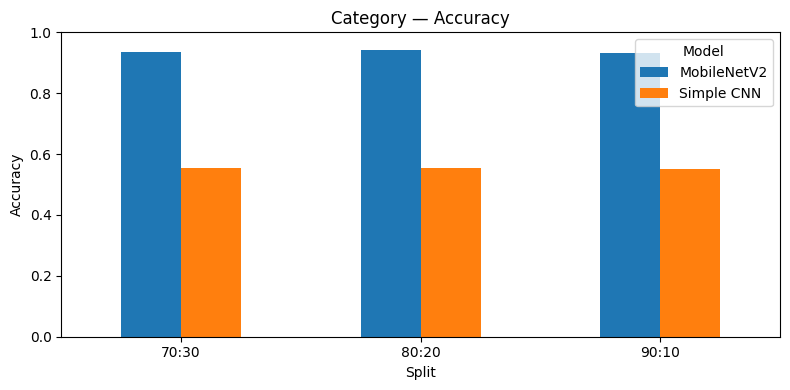

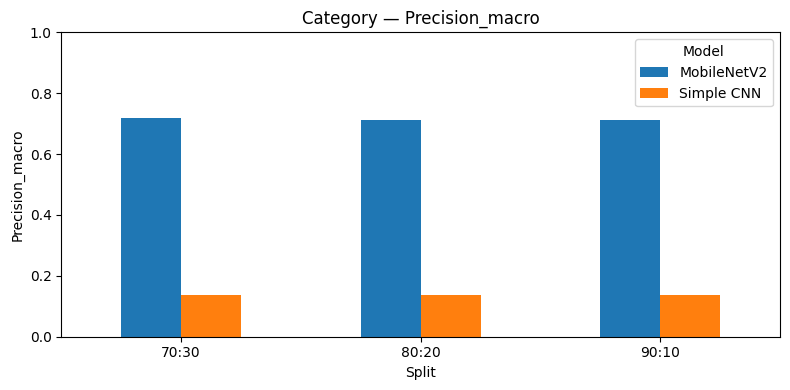

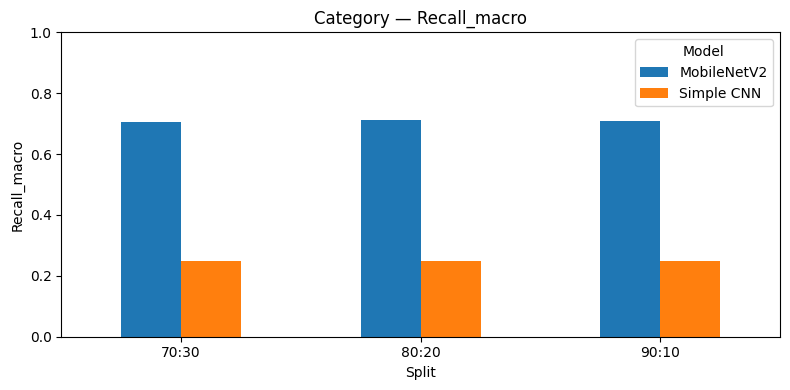

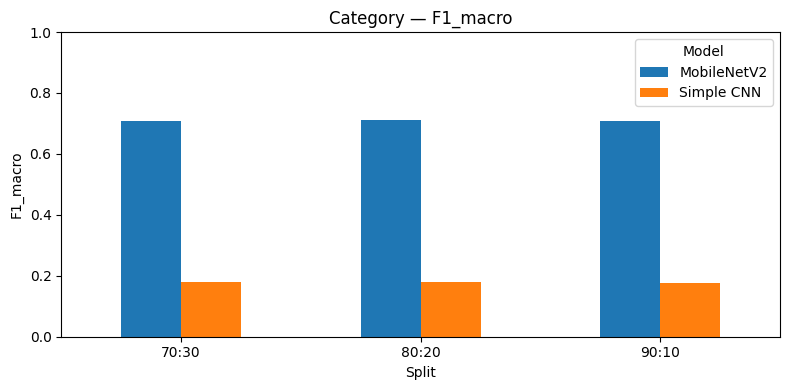

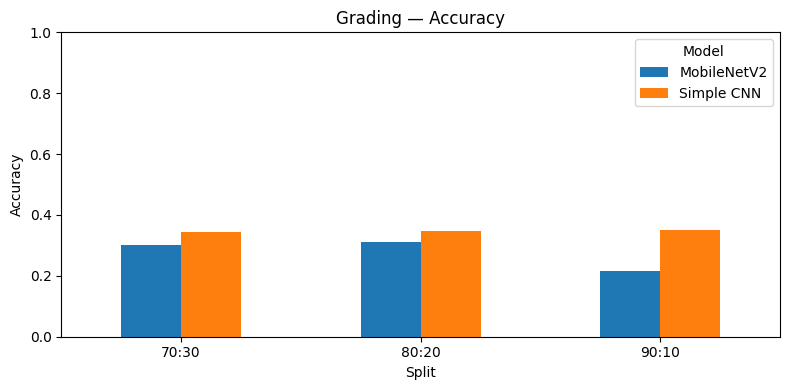

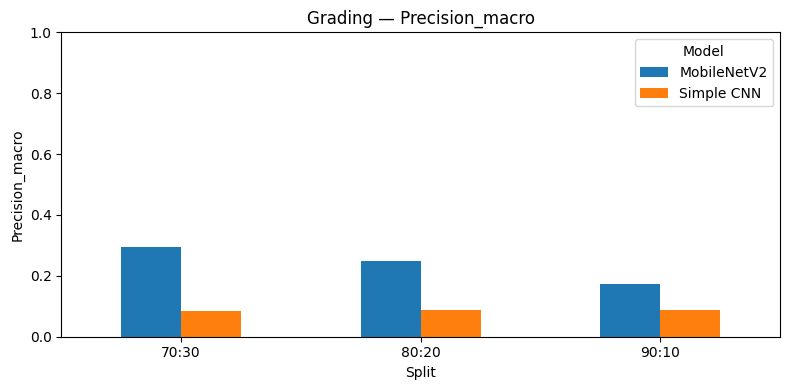

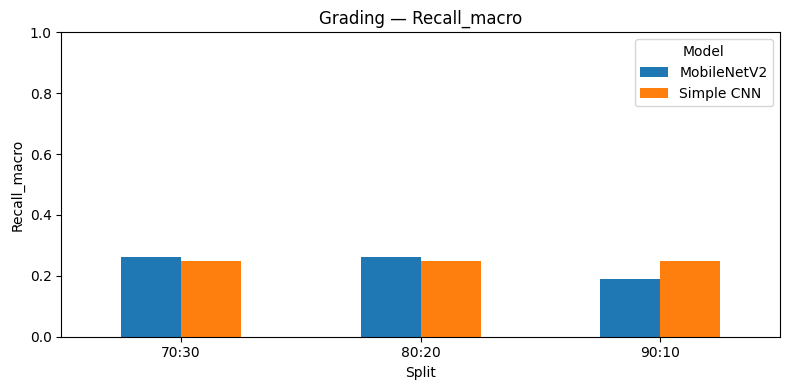

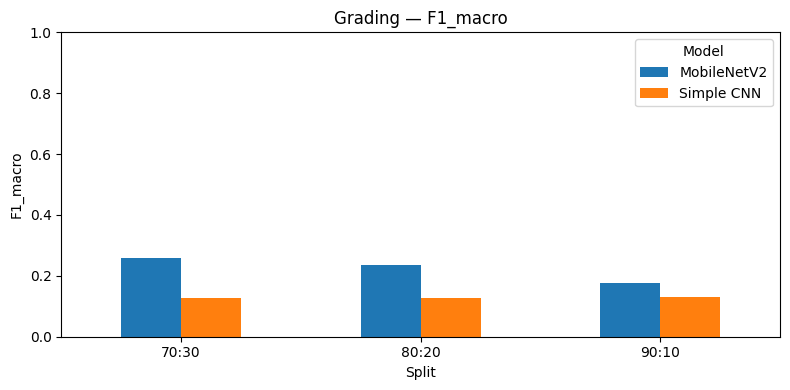

In [ ]:
for task_name in split_df["Task"].unique():
    task_results = split_df[split_df["Task"] == task_name]

    for metric in [
        "Accuracy", "Precision_macro",
        "Recall_macro", "F1_macro"
    ]:
        pivot = task_results.pivot(
            index="Split",
            columns="Model",
            values=metric
        )

        pivot.plot(kind="bar", figsize=(8, 4))
        plt.title(f"{task_name} — {metric}")
        plt.ylabel(metric)
        plt.ylim(0, 1)
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

In [ ]:
TASKS = {
    "Category": (
        X_category,
        y_category,
        CATEGORY_CLASSES
    ),
    "Grading": (
        X_grade,
        y_grade,
        GRADE_CLASSES
    )
}

print("TASKS berhasil dibuat!")
for task_name, (X, y, class_names) in TASKS.items():
    print(f"\nTask: {task_name}")
    print("X shape:", X.shape)
    print("y shape:", y.shape)
    print("Jumlah kelas:", len(class_names))
    print("Nama kelas:", class_names)

TASKS berhasil dibuat!

Task: Category
X shape: (1200, 224, 224, 3)
y shape: (1200,)
Jumlah kelas: 4
Nama kelas: ['Shirt', 'T-Shirt', 'Pants', 'Jacket']

Task: Grading
X shape: (1200, 224, 224, 3)
y shape: (1200,)
Jumlah kelas: 4
Nama kelas: ['A', 'B', 'C', 'D']


In [ ]:
cv_results = []

for task_name, (X, y, class_names) in TASKS.items():
    print("\n========== 5-FOLD:", task_name, "==========")

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=SEED
    )

    for model_name in MODEL_BUILDERS:
        for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):
            X_train_all, X_test = X[train_idx], X[test_idx]
            y_train_all, y_test = y[train_idx], y[test_idx]

            X_train, X_val, y_train, y_val = train_test_split(
                X_train_all, y_train_all,
                test_size=0.15,
                random_state=SEED,
                stratify=y_train_all
            )

            print(f"{model_name} — Fold {fold}/5")

            result, model, pred, history = run_experiment(
                task_name,
                model_name,
                f"Fold {fold}",
                X_train, y_train,
                X_test, y_test,
                class_names,
                validation_data=(X_val, y_val)
            )

            result["Fold"] = fold
            cv_results.append(result)

cv_df = pd.DataFrame(cv_results)
display(cv_df.round(4))


========== 5-FOLD: Category ==========
Simple CNN — Fold 1/5
Epoch 1/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step - accuracy: 0.5441 - loss: 1.0698 - val_accuracy: 0.5556 - val_loss: 1.0381
Epoch 2/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.5527 - loss: 1.0083 - val_accuracy: 0.5556 - val_loss: 0.9310
Epoch 3/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.5699 - loss: 0.9634 - val_accuracy: 0.5556 - val_loss: 0.9161


Simple CNN — Fold 2/5
Epoch 1/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.5343 - loss: 1.0873 - val_accuracy: 0.5556 - val_loss: 1.0051
Epoch 2/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - accuracy: 0.5502 - loss: 1.0118 - val_accuracy: 0.5556 - val_loss: 0.9041
Epoch 3/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.5478 - loss: 0.9532 - val_accuracy: 0.5833 - val_loss: 0.8577
Simple CNN — Fold 3/5
Epoch 1/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - accuracy: 0.5319 - loss: 1.0993 - val_accuracy: 0.5556 - val_loss: 1.0423
Epoch 2/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - accuracy: 0.5490 - loss: 1.0325 - val_accuracy: 0.5556 - val_loss: 0.9846
Epoch 3/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - accuracy: 0.5478 - loss: 0.9746 - val_accuracy: 0.5556 - val_loss: 1.0135
Simple CNN — Fold 4/5
Epoch 1/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step - accuracy: 0.5429 - loss: 1.0826 - val_accuracy: 0.5556 - val_loss: 1.0445
Epoch 2/3
51/51 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - accura

,Task,Model,Split,Train,Test,Accuracy,Precision_macro,Recall_macro,F1_macro,Fold
0,Category,Simple CNN,Fold 1,816,240,0.5542,0.1385,0.2500,0.1783,1
1,Category,Simple CNN,Fold 2,816,240,0.5500,0.2748,0.2676,0.2291,2
2,Category,Simple CNN,Fold 3,816,240,0.5542,0.1385,0.2500,0.1783,3
3,Category,Simple CNN,Fold 4,816,240,0.5500,0.1375,0.2500,0.1774,4
4,Category,Simple CNN,Fold 5,816,240,0.5500,0.1375,0.2500,0.1774,5
5,Category,MobileNetV2,Fold 1,816,240,0.9458,0.7080,0.7211,0.7144,1
6,Category,MobileNetV2,Fold 2,816,240,0.9292,0.7097,0.7014,0.7045,2
7,Category,MobileNetV2,Fold 3,816,240,0.9458,0.9694,0.7938,0.8395,3
8,Category,MobileNetV2,Fold 4,816,240,0.9458,0.7173,0.7142,0.7154,4
9,Category,MobileNetV2,Fold 5,816,240,0.9292,0.7047,0.7067,0.7053,5


In [ ]:
cv_summary = cv_df.groupby(["Task", "Model"])[
    ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"]
].agg(["mean", "std"])

display(cv_summary.round(4))

Accuracy         Precision_macro         Recall_macro  \
                         mean     std            mean     std         mean   
Task     Model                                                               
Category MobileNetV2   0.9392  0.0091          0.7618  0.1161       0.7274   
         Simple CNN    0.5517  0.0023          0.1654  0.0612       0.2535   
Grading  MobileNetV2   0.3125  0.0561          0.2851  0.0619       0.2772   
         Simple CNN    0.3450  0.0019          0.0863  0.0005       0.2500   

                             F1_macro          
                         std     mean     std  
Task     Model                                 
Category MobileNetV2  0.0378   0.7358  0.0582  
         Simple CNN   0.0079   0.1881  0.0229  
Grading  MobileNetV2  0.0389   0.2601  0.0344  
         Simple CNN   0.0000   0.1283  0.0005

In [ ]:
def rule_based_grade(condition):
    if condition == 5:
        return "A"
    elif condition == 4:
        return "B"
    elif condition == 3:
        return "C"
    elif condition in (1, 2):
        return "D"
    return "Unknown"

grading_rule_df = df_grade[
    ["condition", "label", "holes", "stains", "pilling"]
].copy()

grading_rule_df["rule_grade"] = grading_rule_df[
    "condition"
].apply(rule_based_grade)

display(grading_rule_df.head(20))

grading_rule_df.to_csv(
    "thrifty_rule_based_grading_log.csv",
    index=False
)

,condition,label,holes,stains,pilling,rule_grade
0,2,D,0,1,5,D
1,3,C,0,2,5,C
2,3,C,0,1,1,C
3,2,D,0,1,1,D
4,5,A,0,1,5,A
5,5,A,0,7,5,A
6,5,A,0,1,5,A
7,5,A,0,1,5,A
8,3,C,0,0,5,C
9,3,C,0,2,5,C


In [ ]:
check_vars = [
    "df_grade",
    "grading_rule_df",
    "cv_df",
    "cv_summary",
    "split_df",
    "saved_models",
    "saved_predictions"
]

for name in check_vars:
    exists = name in globals()
    print(f"{name}: {'ADA' if exists else 'TIDAK ADA'}")

    if exists:
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print("  Shape:", obj.shape)
        elif isinstance(obj, dict):
            print("  Jumlah item:", len(obj))

df_grade: ADA
  Shape: (1200, 8)
grading_rule_df: ADA
  Shape: (1200, 6)
cv_df: ADA
  Shape: (20, 10)
cv_summary: ADA
  Shape: (4, 8)
split_df: ADA
  Shape: (12, 9)
saved_models: ADA
  Jumlah item: 12
saved_predictions: ADA
  Jumlah item: 12


In [ ]:
import pandas as pd
from datasets import load_dataset

if "df_grade" not in globals():
    print("Memuat ulang data grading saja; tidak ada training.")

    GRADE_DATASET = "wargoninnovation/clothingdatasetsecondhand"
    GRADE_MAP = {5: "A", 4: "B", 3: "C", 2: "D", 1: "D"}

    stream = load_dataset(
        GRADE_DATASET,
        split="train",
        streaming=True
    )

    records = []

    for row in stream:
        condition = row.get("condition")
        image = row.get("image")

        if condition not in GRADE_MAP or image is None:
            continue

        records.append({
            "image": image.convert("RGB"),
            "label": GRADE_MAP[int(condition)],
            "condition": int(condition),
            "holes": row.get("holes"),
            "stains": row.get("stains"),
            "pilling": row.get("pilling"),
            "source": GRADE_DATASET
        })

        if len(records) >= 1200:
            break

    df_grade = pd.DataFrame(records)

print("Data grading tersedia:", df_grade.shape)
display(df_grade.head())

Data grading tersedia: (1200, 8)


,image,label,condition,holes,stains,pilling,source,item_id
0,<PIL.Image.Image image mode=RGB size=224x224 a...,D,2,0,1,5,wargoninnovation/clothingdatasetsecondhand,front_2023_09_13_05_18_15.png
1,<PIL.Image.Image image mode=RGB size=224x224 a...,C,3,0,2,5,wargoninnovation/clothingdatasetsecondhand,front_2023_11_06_07_07_20.png
2,<PIL.Image.Image image mode=RGB size=224x224 a...,C,3,0,1,1,wargoninnovation/clothingdatasetsecondhand,front_2023_06_29_13_15_53.png
3,<PIL.Image.Image image mode=RGB size=224x224 a...,D,2,0,1,1,wargoninnovation/clothingdatasetsecondhand,back_2023_12_27_12_24_34.png
4,<PIL.Image.Image image mode=RGB size=224x224 a...,A,5,0,1,5,wargoninnovation/clothingdatasetsecondhand,front_2023_12_21_12_28_39.png


In [ ]:
def rule_based_grade(condition):
    if pd.isna(condition):
        return "Unknown"

    condition = int(condition)

    if condition == 5:
        return "A"
    elif condition == 4:
        return "B"
    elif condition == 3:
        return "C"
    elif condition in (1, 2):
        return "D"
    return "Unknown"


grading_rule_df = df_grade.copy()

grading_rule_df["rule_grade"] = grading_rule_df[
    "condition"
].apply(rule_based_grade)

print("Rule-based grading berhasil dibuat.")
display(
    grading_rule_df[
        ["condition", "label", "rule_grade", "holes", "stains", "pilling"]
    ].head(20)
)

Rule-based grading berhasil dibuat.


,condition,label,rule_grade,holes,stains,pilling
0,2,D,D,0,1,5
1,3,C,C,0,2,5
2,3,C,C,0,1,1
3,2,D,D,0,1,1
4,5,A,A,0,1,5
5,5,A,A,0,7,5
6,5,A,A,0,1,5
7,5,A,A,0,1,5
8,3,C,C,0,0,5
9,3,C,C,0,2,5


,Jumlah sampel
rule_grade,
A,311
B,184
C,414
D,291


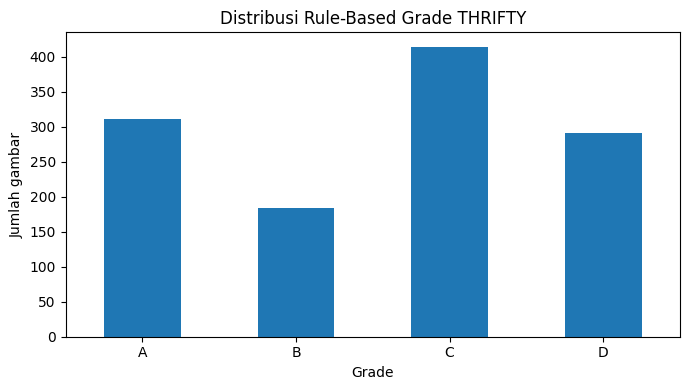

In [ ]:
import matplotlib.pyplot as plt

grade_order = ["A", "B", "C", "D"]

grade_counts = (
    grading_rule_df["rule_grade"]
    .value_counts()
    .reindex(grade_order, fill_value=0)
)

display(grade_counts.rename("Jumlah sampel").to_frame())

grade_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Distribusi Rule-Based Grade THRIFTY")
plt.xlabel("Grade")
plt.ylabel("Jumlah gambar")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
def safe_numeric(series):
    return pd.to_numeric(series, errors="coerce")

for col in ["holes", "stains", "pilling"]:
    if col in grading_rule_df.columns:
        grading_rule_df[col + "_numeric"] = safe_numeric(
            grading_rule_df[col]
        )

defect_columns = [
    col for col in ["holes_numeric", "stains_numeric", "pilling_numeric"]
    if col in grading_rule_df.columns
]

if defect_columns:
    defect_summary = grading_rule_df.groupby("rule_grade")[
        defect_columns
    ].mean()

    print("Rata-rata atribut cacat per rule-based grade:")
    display(defect_summary.round(3))
else:
    print("Kolom atribut cacat numerik tidak tersedia.")

Rata-rata atribut cacat per rule-based grade:


,holes_numeric,stains_numeric,pilling_numeric
rule_grade,,,
A,0.000,1.592,4.997
B,0.054,1.880,4.505
C,0.111,1.391,3.937
D,0.230,1.436,3.570


In [ ]:
import os

os.makedirs("thrifty_outputs", exist_ok=True)

grading_rule_df.to_csv(
    "thrifty_outputs/thrifty_rule_based_grading.csv",
    index=False
)

grade_counts.rename("count").to_csv(
    "thrifty_outputs/thrifty_grade_distribution.csv"
)

if "defect_summary" in globals():
    defect_summary.to_csv(
        "thrifty_outputs/thrifty_defect_summary_by_grade.csv"
    )

print("File grading tersimpan:")
print(os.listdir("thrifty_outputs"))

File grading tersimpan:
['thrifty_grade_distribution.csv', 'thrifty_rule_based_grading.csv', 'thrifty_defect_summary_by_grade.csv']


In [ ]:
if "cv_df" in globals() and isinstance(cv_df, pd.DataFrame):
    print("Cross-validation results:", cv_df.shape)
    display(cv_df.round(4))

    if "cv_summary" in globals():
        print("Cross-validation summary:")
        display(cv_summary.round(4))

elif "cv_results" in globals() and len(cv_results) > 0:
    cv_df = pd.DataFrame(cv_results)
    print("Cross-validation results dipulihkan dari cv_results.")
    display(cv_df.round(4))

else:
    print(
        "Hasil CV tidak tersedia sebagai variabel aktif. "
        "Output lama masih bisa dilihat di cell sebelumnya, "
        "tetapi model tidak akan dilatih ulang oleh cell ini."
    )


if "split_df" in globals() and isinstance(split_df, pd.DataFrame):
    print("Split results:", split_df.shape)
    display(split_df.round(4))
else:
    print(
        "split_df tidak tersedia. Cell eksperimen split sebelumnya "
        "gagal, jadi jangan menganggap tabel split berhasil dibuat "
        "dari variabel yang hilang."
    )

Cross-validation results: (20, 10)


,Task,Model,Split,Train,Test,Accuracy,Precision_macro,Recall_macro,F1_macro,Fold
0,Category,Simple CNN,Fold 1,816,240,0.5542,0.1385,0.2500,0.1783,1
1,Category,Simple CNN,Fold 2,816,240,0.5500,0.2748,0.2676,0.2291,2
2,Category,Simple CNN,Fold 3,816,240,0.5542,0.1385,0.2500,0.1783,3
3,Category,Simple CNN,Fold 4,816,240,0.5500,0.1375,0.2500,0.1774,4
4,Category,Simple CNN,Fold 5,816,240,0.5500,0.1375,0.2500,0.1774,5
5,Category,MobileNetV2,Fold 1,816,240,0.9458,0.7080,0.7211,0.7144,1
6,Category,MobileNetV2,Fold 2,816,240,0.9292,0.7097,0.7014,0.7045,2
7,Category,MobileNetV2,Fold 3,816,240,0.9458,0.9694,0.7938,0.8395,3
8,Category,MobileNetV2,Fold 4,816,240,0.9458,0.7173,0.7142,0.7154,4
9,Category,MobileNetV2,Fold 5,816,240,0.9292,0.7047,0.7067,0.7053,5


Cross-validation summary:


Accuracy         Precision_macro         Recall_macro  \
                         mean     std            mean     std         mean   
Task     Model                                                               
Category MobileNetV2   0.9392  0.0091          0.7618  0.1161       0.7274   
         Simple CNN    0.5517  0.0023          0.1654  0.0612       0.2535   
Grading  MobileNetV2   0.3125  0.0561          0.2851  0.0619       0.2772   
         Simple CNN    0.3450  0.0019          0.0863  0.0005       0.2500   

                             F1_macro          
                         std     mean     std  
Task     Model                                 
Category MobileNetV2  0.0378   0.7358  0.0582  
         Simple CNN   0.0079   0.1881  0.0229  
Grading  MobileNetV2  0.0389   0.2601  0.0344  
         Simple CNN   0.0000   0.1283  0.0005

Split results: (12, 9)


,Task,Model,Split,Train,Test,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Category,Simple CNN,70:30,714,360,0.5528,0.1382,0.2500,0.1780
1,Category,MobileNetV2,70:30,714,360,0.9361,0.7178,0.7040,0.7090
2,Category,Simple CNN,80:20,816,240,0.5542,0.1385,0.2500,0.1783
3,Category,MobileNetV2,80:20,816,240,0.9417,0.7113,0.7105,0.7108
4,Category,Simple CNN,90:10,918,120,0.5500,0.1375,0.2500,0.1774
5,Category,MobileNetV2,90:10,918,120,0.9333,0.7116,0.7071,0.7085
6,Grading,Simple CNN,70:30,714,360,0.3444,0.0861,0.2500,0.1281
7,Grading,MobileNetV2,70:30,714,360,0.3000,0.2950,0.2624,0.2575
8,Grading,Simple CNN,80:20,816,240,0.3458,0.0865,0.2500,0.1285
9,Grading,MobileNetV2,80:20,816,240,0.3125,0.2475,0.2632,0.2365


In [ ]:
if "cv_df" in globals() and isinstance(cv_df, pd.DataFrame):
    cv_df.to_csv(
        "thrifty_outputs/thrifty_5fold_results.csv",
        index=False
    )

    cv_metrics = [
        "Accuracy",
        "Precision_macro",
        "Recall_macro",
        "F1_macro"
    ]

    available_metrics = [
        col for col in cv_metrics if col in cv_df.columns
    ]

    if available_metrics and "Task" in cv_df.columns and "Model" in cv_df.columns:
        cv_summary = cv_df.groupby(["Task", "Model"])[
            available_metrics
        ].agg(["mean", "std"])

        cv_summary.to_csv(
            "thrifty_outputs/thrifty_5fold_summary.csv"
        )

        display(cv_summary.round(4))

    print("Hasil CV disimpan tanpa training ulang.")
else:
    print("Tidak ada DataFrame CV aktif untuk disimpan.")

Accuracy         Precision_macro         Recall_macro  \
                         mean     std            mean     std         mean   
Task     Model                                                               
Category MobileNetV2   0.9392  0.0091          0.7618  0.1161       0.7274   
         Simple CNN    0.5517  0.0023          0.1654  0.0612       0.2535   
Grading  MobileNetV2   0.3125  0.0561          0.2851  0.0619       0.2772   
         Simple CNN    0.3450  0.0019          0.0863  0.0005       0.2500   

                             F1_macro          
                         std     mean     std  
Task     Model                                 
Category MobileNetV2  0.0378   0.7358  0.0582  
         Simple CNN   0.0079   0.1881  0.0229  
Grading  MobileNetV2  0.0389   0.2601  0.0344  
         Simple CNN   0.0000   0.1283  0.0005

Hasil CV disimpan tanpa training ulang.


Setup

In [ ]:
import sys, subprocess, os, time, warnings
warnings.filterwarnings("ignore")

def _ensure(mod, pkg):
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

for _mod, _pkg in [("xgboost", "xgboost"), ("lightgbm", "lightgbm"),
                   ("skimage", "scikit-image"), ("joblib", "joblib")]:
    _ensure(_mod, _pkg)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed
from scipy import ndimage as ndi

from skimage.color import rgb2hsv, rgb2gray
from skimage.feature import local_binary_pattern, hog, graycomatrix, graycoprops, canny
from skimage.transform import resize

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_predict
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, r2_score)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, LGBMRegressor

SEED = globals().get("SEED", 42)
IMG_SIZE = globals().get("IMG_SIZE", (224, 224))
QUICK_MODE = False          # True = pohon lebih sedikit (lebih cepat)
RUN_EMBEDDINGS = True       # True = pakai fitur MobileNetV2 (hybrid)
N_EST = 120 if QUICK_MODE else 300

CATEGORY_CLASSES = ["Shirt", "T-Shirt", "Pants", "Jacket"]
GRADE_CLASSES = ["A", "B", "C", "D"]
SPLITS = {"70:30": 0.30, "80:20": 0.20, "90:10": 0.10}
os.makedirs("thrifty_outputs", exist_ok=True)
print("Setup selesai | SEED =", SEED, "| N_EST =", N_EST)

Setup selesai | SEED = 42 | N_EST = 300


In [ ]:
if "image_to_array" not in globals():
    def image_to_array(image):
        image = image.convert("RGB").resize(IMG_SIZE)
        return np.asarray(image, dtype=np.uint8)

if "prepare_arrays" not in globals():
    def prepare_arrays(df, classes):
        class_to_id = {name: i for i, name in enumerate(classes)}
        X = np.stack([image_to_array(im) for im in df["image"]])
        y = np.asarray([class_to_id[l] for l in df["label"]], dtype=np.int32)
        return X, y

def _load_category(max_n=1200):
    from datasets import load_dataset
    cmap = {"shirts": "Shirt", "shirt": "Shirt", "tshirts": "T-Shirt", "t-shirt": "T-Shirt",
            "tshirt": "T-Shirt", "jeans": "Pants", "trousers": "Pants", "track pants": "Pants",
            "shorts": "Pants", "pants": "Pants", "joggers": "Pants", "jackets": "Jacket",
            "jacket": "Jacket"}
    stream = load_dataset("ashraq/fashion-product-images-small", split="train", streaming=True)
    rec = []
    for row in stream:
        lab = cmap.get(str(row.get("articleType")).strip().lower())
        img = row.get("image")
        if lab is None or img is None:
            continue
        rec.append({"image": img.convert("RGB"), "label": lab})
        if len(rec) >= max_n:
            break
    return pd.DataFrame(rec)

def _load_grade(max_n=1200):
    from datasets import load_dataset
    gmap = {5: "A", 4: "B", 3: "C", 2: "D", 1: "D"}
    stream = load_dataset("wargoninnovation/clothingdatasetsecondhand", split="train", streaming=True)
    rec = []
    for row in stream:
        cond, img = row.get("condition"), row.get("image")
        if cond not in gmap or img is None:
            continue
        rec.append({"image": img.convert("RGB"), "label": gmap[int(cond)], "condition": int(cond),
                    "holes": row.get("holes"), "stains": row.get("stains"),
                    "pilling": row.get("pilling")})
        if len(rec) >= max_n:
            break
    return pd.DataFrame(rec)

if "df_category" not in globals():
    print("df_category tidak ada, memuat ulang ...")
    df_category = _load_category()
if "df_grade" not in globals():
    print("df_grade tidak ada, memuat ulang ...")
    df_grade = _load_grade()

if "X_category" not in globals() or "y_category" not in globals():
    X_category, y_category = prepare_arrays(df_category, CATEGORY_CLASSES)
if "X_grade" not in globals() or "y_grade" not in globals():
    X_grade, y_grade = prepare_arrays(df_grade, GRADE_CLASSES)

# atribut cacat numerik untuk gabungan Category + Defect + Grading
ATTR_COLS = ["holes", "stains", "pilling"]
A_grade = np.column_stack([pd.to_numeric(df_grade[c], errors="coerce") for c in ATTR_COLS]).astype(float)
for j in range(A_grade.shape[1]):
    med = np.nanmedian(A_grade[:, j])
    A_grade[np.isnan(A_grade[:, j]), j] = med

print("Category:", X_category.shape, y_category.shape, "| kelas:", np.bincount(y_category))
print("Grading :", X_grade.shape, y_grade.shape, "| kelas:", np.bincount(y_grade))
print("Atribut cacat:", A_grade.shape, "(holes, stains, pilling)")

Category: (1200, 224, 224, 3) (1200,) | kelas: [317 663 203  17]
Grading : (1200, 224, 224, 3) (1200,) | kelas: [311 184 414 291]
Atribut cacat: (1200, 3) (holes, stains, pilling)


Feature


In [ ]:
def foreground_mask(img):
    """Pisahkan pakaian dari background dengan membandingkan ke warna tepi gambar."""
    border = np.concatenate([img[0, :, :], img[-1, :, :], img[:, 0, :], img[:, -1, :]], axis=0)
    bg = np.median(border, axis=0)
    diff = np.abs(img.astype(np.int16) - bg.astype(np.int16)).max(axis=2)
    mask = diff > 30
    if mask.mean() < 0.02:
        mask = np.ones(mask.shape, dtype=bool)
    return mask

def extract_features(img):
    """Ubah 1 gambar (224x224x3 uint8) menjadi vektor fitur numerik."""
    h, w = img.shape[:2]
    mask = foreground_mask(img)
    f = []

    # 1) Bentuk
    ys, xs = np.where(mask)
    bh = (ys.max() - ys.min() + 1) / h
    bw = (xs.max() - xs.min() + 1) / w
    area = mask.mean()
    f += [area, bh, bw, bw / (bh + 1e-6), area / (bh * bw + 1e-6)]

    # 2) Warna (hanya piksel pakaian)
    px = img[mask].astype(np.float32) / 255.0
    hsv = rgb2hsv(px.reshape(-1, 1, 3)).reshape(-1, 3)
    f += list(px.mean(0)) + list(px.std(0)) + list(hsv.mean(0)) + list(hsv.std(0))
    for c in range(3):
        f += list(np.histogram(hsv[:, c], bins=8, range=(0, 1))[0] / len(hsv))

    # 3) Tekstur: LBP + GLCM
    gray = (rgb2gray(img) * 255).astype(np.uint8)
    lbp = local_binary_pattern(gray, 8, 1, "uniform")
    lbp_hist = np.bincount(lbp[mask].astype(int), minlength=10)[:10] / mask.sum()
    f += list(lbp_hist)
    g = gray[::2, ::2] // 8
    glcm = graycomatrix(g, [1, 3], [0, np.pi / 2], levels=32, symmetric=True, normed=True)
    for prop in ["contrast", "homogeneity", "energy", "correlation"]:
        f.append(float(graycoprops(glcm, prop).mean()))

    # 4) Tepi & ketajaman
    edges = canny(gray / 255.0, sigma=2)
    f.append(edges[mask].mean())
    f.append(np.log1p(ndi.laplace(gray.astype(np.float32))[mask].var()))

    # 5) Proxy cacat: lubang, noda/bercak, keseragaman warna
    filled = ndi.binary_fill_holes(mask)
    f.append(((filled & ~mask).sum()) / (filled.sum() + 1e-6))
    med_col = np.median(px, axis=0)
    dev = np.linalg.norm(px - med_col, axis=1)
    f += [dev.mean(), (dev > 0.25).mean()]
    gm = gray[mask].astype(np.float32)
    f += [(gm < np.median(gm) - 40).mean(), (gm > np.median(gm) + 40).mean()]

    # 6) HOG (siluet/garis)
    small = resize(gray, (64, 64), anti_aliasing=True)
    f += list(hog(small, orientations=9, pixels_per_cell=(16, 16),
                  cells_per_block=(2, 2), feature_vector=True))
    return np.asarray(f, dtype=np.float32)

def build_feature_names(n_hog):
    names = ["mask_area", "bbox_h", "bbox_w", "bbox_aspect", "bbox_fill"]
    names += [f"mean_{c}" for c in "RGB"] + [f"std_{c}" for c in "RGB"]
    names += [f"hsv_mean_{c}" for c in "HSV"] + [f"hsv_std_{c}" for c in "HSV"]
    names += [f"hist_{c}_{i}" for c in "HSV" for i in range(8)]
    names += [f"lbp_{i}" for i in range(10)]
    names += ["glcm_contrast", "glcm_homogeneity", "glcm_energy", "glcm_correlation"]
    names += ["edge_density", "laplacian_logvar"]
    names += ["hole_ratio", "color_dev_mean", "color_dev_frac", "rel_dark_frac", "rel_light_frac"]
    names += [f"hog_{i}" for i in range(n_hog)]
    return names

def extract_all(X, desc=""):
    t0 = time.time()
    feats = Parallel(n_jobs=-1, batch_size=16)(delayed(extract_features)(x) for x in X)
    feats = np.vstack(feats)
    print(f"{desc}: {feats.shape} dalam {time.time() - t0:.1f} detik")
    return feats

_dummy = extract_features(X_category[0])
N_HC = len(_dummy)
FEATURE_NAMES = build_feature_names(N_HC - len(build_feature_names(0)))
assert len(FEATURE_NAMES) == N_HC, (len(FEATURE_NAMES), N_HC)
print("Jumlah fitur handcrafted per gambar:", N_HC)

FEAT_CACHE = "thrifty_outputs/handcrafted_features.npz"
if os.path.exists(FEAT_CACHE):
    _c = np.load(FEAT_CACHE)
    if _c["cat"].shape[0] == len(X_category) and _c["grade"].shape[0] == len(X_grade):
        X_hc_cat, X_hc_grade = _c["cat"], _c["grade"]
        print("Fitur handcrafted dimuat dari cache.")
if "X_hc_cat" not in globals():
    X_hc_cat = extract_all(X_category, "Category")
    X_hc_grade = extract_all(X_grade, "Grading")
    np.savez_compressed(FEAT_CACHE, cat=X_hc_cat, grade=X_hc_grade)

Jumlah fitur handcrafted per gambar: 386
Category: (1200, 386) dalam 45.0 detik
Grading: (1200, 386) dalam 50.1 detik


Fungsi embedding MobileNetV2

In [ ]:
_EMB_MODEL = None

def extract_embeddings(X, batch=32):
    global _EMB_MODEL
    import tensorflow as tf
    if _EMB_MODEL is None:
        _EMB_MODEL = tf.keras.applications.MobileNetV2(
            input_shape=(224, 224, 3), include_top=False, weights="imagenet", pooling="avg")
    out = []
    for i in range(0, len(X), batch):
        xb = tf.keras.applications.mobilenet_v2.preprocess_input(X[i:i + batch].astype("float32"))
        out.append(_EMB_MODEL(xb, training=False).numpy())
    return np.vstack(out)

embedding dan susun set fitur

In [ ]:
EMB_CACHE = "thrifty_outputs/mobilenet_embeddings.npz"
if RUN_EMBEDDINGS:
    if os.path.exists(EMB_CACHE):
        _c = np.load(EMB_CACHE)
        if _c["cat"].shape[0] == len(X_category) and _c["grade"].shape[0] == len(X_grade):
            X_emb_cat, X_emb_grade = _c["cat"], _c["grade"]
            print("Embedding dimuat dari cache.")
    if "X_emb_cat" not in globals():
        t0 = time.time()
        X_emb_cat = extract_embeddings(X_category)
        X_emb_grade = extract_embeddings(X_grade)
        np.savez_compressed(EMB_CACHE, cat=X_emb_cat, grade=X_emb_grade)
        print(f"Embedding: {X_emb_cat.shape} & {X_emb_grade.shape} dalam {time.time() - t0:.1f} detik")

FEATURES = {
    "Category": {"Handcrafted": X_hc_cat},
    "Grading": {"Handcrafted": X_hc_grade},
}
if RUN_EMBEDDINGS:
    FEATURES["Category"]["MobileNet embedding"] = X_emb_cat
    FEATURES["Category"]["Hybrid"] = np.hstack([X_hc_cat, X_emb_cat])
    FEATURES["Grading"]["MobileNet embedding"] = X_emb_grade
    FEATURES["Grading"]["Hybrid"] = np.hstack([X_hc_grade, X_emb_grade])
for t, d in FEATURES.items():
    print(t, {k: v.shape for k, v in d.items()})

Embedding: (1200, 1280) & (1200, 1280) dalam 129.9 detik
Category {'Handcrafted': (1200, 386), 'MobileNet embedding': (1200, 1280), 'Hybrid': (1200, 1666)}
Grading {'Handcrafted': (1200, 386), 'MobileNet embedding': (1200, 1280), 'Hybrid': (1200, 1666)}


Model, pipeline, dan fungsi evaluasi

In [ ]:
BASE_MODELS = ["Logistic Regression", "SVM (RBF)", "Decision Tree",
               "Random Forest", "XGBoost", "LightGBM"]

def make_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced"),
        "SVM (RBF)": SVC(C=10, kernel="rbf", gamma="scale", class_weight="balanced"),
        "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=3,
                                                class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=N_EST, min_samples_leaf=1,
                                                class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=N_EST, max_depth=4, learning_rate=0.08,
                                 subsample=0.8, colsample_bytree=0.6, eval_metric="mlogloss",
                                 n_jobs=-1, random_state=SEED, verbosity=0),
        "LightGBM": LGBMClassifier(n_estimators=N_EST, learning_rate=0.05, num_leaves=15,
                                   min_child_samples=5, subsample=0.8, subsample_freq=1,
                                   colsample_bytree=0.6, class_weight="balanced",
                                   n_jobs=-1, random_state=SEED, verbose=-1),
        # grade itu ordinal (A>B>C>D): regresi lalu dibulatkan
        "LightGBM Ordinal": LGBMRegressor(n_estimators=N_EST, learning_rate=0.05, num_leaves=15,
                                          min_child_samples=5, subsample=0.8, subsample_freq=1,
                                          colsample_bytree=0.6, n_jobs=-1,
                                          random_state=SEED, verbose=-1),
    }

def make_preprocessor(feature_set, n_hc):
    if feature_set == "Handcrafted":
        return StandardScaler()
    emb_block = Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=64, random_state=SEED))])
    if feature_set == "MobileNet embedding":
        return emb_block
    return ColumnTransformer([("hc", StandardScaler(), slice(0, n_hc)),
                              ("emb", emb_block, slice(n_hc, None))])

def build_pipeline(model_name, feature_set, n_hc):
    return Pipeline([("prep", make_preprocessor(feature_set, n_hc)),
                     ("clf", make_models()[model_name])])

def fit_predict(pipe, model_name, Xtr, ytr, Xte):
    if model_name == "XGBoost":
        pipe.fit(Xtr, ytr, clf__sample_weight=compute_sample_weight("balanced", ytr))
    else:
        pipe.fit(Xtr, ytr)
    pred = pipe.predict(Xte)
    if "Ordinal" in model_name:
        pred = np.clip(np.rint(pred), 0, ytr.max()).astype(int)
    return pred

def score_row(y_true, y_pred, task):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Within1_Acc": float(np.mean(np.abs(y_true - y_pred) <= 1)) if task == "Grading" else np.nan,
    }

def iter_protocols(y):
    """Split sama persis dengan notebook utama (SEED & stratify sama) -> perbandingan adil."""
    for split_name, test_size in SPLITS.items():
        tr, te = train_test_split(np.arange(len(y)), test_size=test_size,
                                  random_state=SEED, stratify=y)
        yield "Split", split_name, tr, te
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for fold, (tr, te) in enumerate(skf.split(np.zeros(len(y)), y), start=1):
        yield "CV", f"Fold {fold}", tr, te

PRED_STORE = {}

def _store(key, y_true, y_pred):
    yt, yp = PRED_STORE.setdefault(key, ([], []))
    yt.extend(list(y_true)); yp.extend(list(y_pred))

def evaluate_baseline(task, y, feature_sets, n_hc, model_names, approach="Baseline"):
    rows = []
    for proto, split, tr, te in iter_protocols(y):
        t0 = time.time()
        for fs_name, Xf in feature_sets.items():
            for m in model_names:
                pipe = build_pipeline(m, fs_name, n_hc)
                pred = fit_predict(pipe, m, Xf[tr], y[tr], Xf[te])
                rows.append({"Task": task, "Approach": approach, "Features": fs_name, "Model": m,
                             "Protocol": proto, "Split": split, "Train": len(tr), "Test": len(te),
                             **score_row(y[te], pred, task)})
                if proto == "CV":
                    _store((task, approach, fs_name, m), y[te], pred)
        print(f"[{task}] {proto} {split} selesai ({time.time() - t0:.0f} dtk)")
    return pd.DataFrame(rows)

Eksperimen 1, classical ML murni

In [ ]:
fs_cat = FEATURES["Category"]
fs_grade = FEATURES["Grading"]

res_cat = evaluate_baseline("Category", y_category, fs_cat, N_HC, BASE_MODELS)
res_grade = evaluate_baseline("Grading", y_grade, fs_grade, N_HC, BASE_MODELS)
res_base = pd.concat([res_cat, res_grade], ignore_index=True)
res_base.to_csv("thrifty_outputs/classical_baseline_results.csv", index=False)
print("Selesai:", res_base.shape)

[Category] Split 70:30 selesai (83 dtk)
[Category] Split 80:20 selesai (87 dtk)
[Category] Split 90:10 selesai (96 dtk)
[Category] CV Fold 1 selesai (85 dtk)
[Category] CV Fold 2 selesai (88 dtk)
[Category] CV Fold 3 selesai (90 dtk)
[Category] CV Fold 4 selesai (88 dtk)
[Category] CV Fold 5 selesai (85 dtk)
[Grading] Split 70:30 selesai (137 dtk)
[Grading] Split 80:20 selesai (143 dtk)
[Grading] Split 90:10 selesai (143 dtk)
[Grading] CV Fold 1 selesai (136 dtk)
[Grading] CV Fold 2 selesai (139 dtk)
[Grading] CV Fold 3 selesai (136 dtk)
[Grading] CV Fold 4 selesai (140 dtk)
[Grading] CV Fold 5 selesai (140 dtk)
Selesai: (288, 13)


Persiapan gabungan Category + Grading

In [ ]:
VARIANTS = {
    "Hybrid (tanpa gabungan)":      (False, False),
    "+ Category probs":             (True,  False),
    "+ Defect predictions":         (False, True),
    "+ Category & Defect (Joint)":  (True,  True),
}

# (a) Model Category -> probabilitas kategori untuk gambar grading
_cat_feat_name = "Hybrid" if RUN_EMBEDDINGS else "Handcrafted"
cat_prob_model = build_pipeline("Logistic Regression", _cat_feat_name, N_HC)
cat_prob_model.fit(fs_cat[_cat_feat_name], y_category)
cat_proba_grade = cat_prob_model.predict_proba(fs_grade[_cat_feat_name])

print("Distribusi kategori hasil prediksi pada foto grading:")
print(pd.Series(np.argmax(cat_proba_grade, axis=1)).map(dict(enumerate(CATEGORY_CLASSES))).value_counts())
print("\nCATATAN: foto grading beda domain dengan foto Category. Cek hasil ini secara visual.\n")

# (b) Prediksi atribut cacat dari gambar (out-of-fold, anti-bocor)
def defect_predictions(Xtr, Atr, Xte):
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = np.zeros(Atr.shape, dtype=float)
    te = np.zeros((len(Xte), Atr.shape[1]), dtype=float)
    for j in range(Atr.shape[1]):
        rf = RandomForestRegressor(n_estimators=max(100, N_EST // 2), min_samples_leaf=2,
                                   max_features=0.4, n_jobs=-1, random_state=SEED)
        oof[:, j] = cross_val_predict(rf, Xtr, Atr[:, j], cv=kf)
        te[:, j] = rf.fit(Xtr, Atr[:, j]).predict(Xte)
    return oof, te

_oof_all, _ = defect_predictions(X_hc_grade, A_grade, X_hc_grade[:5])
print("R2 prediksi atribut cacat dari gambar (out-of-fold):")
for j, c in enumerate(ATTR_COLS):
    print(f"  {c:8s}: R2 = {r2_score(A_grade[:, j], _oof_all[:, j]):.3f}")

Distribusi kategori hasil prediksi pada foto grading:
Shirt      725
Pants      251
T-Shirt    160
Jacket      64
Name: count, dtype: int64

CATATAN: foto grading beda domain dengan foto Category. Cek hasil ini secara visual.

R2 prediksi atribut cacat dari gambar (out-of-fold):
  holes   : R2 = -0.077
  stains  : R2 = 0.305
  pilling : R2 = -0.022


In [ ]:
JOINT_MODELS = ["Logistic Regression", "SVM (RBF)", "XGBoost", "LightGBM", "LightGBM Ordinal"]
EMB_G = X_emb_grade if RUN_EMBEDDINGS else None

def evaluate_joint_grading(y, X_hc, X_emb, A, cat_proba, model_names, variants):
    rows = []
    for proto, split, tr, te in iter_protocols(y):
        t0 = time.time()
        oof_attr, te_attr = defect_predictions(X_hc[tr], A[tr], X_hc[te])
        for vname, (use_cat, use_attr) in variants.items():
            blk_tr, blk_te = [X_hc[tr]], [X_hc[te]]
            if use_cat:
                blk_tr.append(cat_proba[tr]); blk_te.append(cat_proba[te])
            if use_attr:
                blk_tr.append(oof_attr);      blk_te.append(te_attr)
            hc_tr, hc_te = np.hstack(blk_tr), np.hstack(blk_te)
            n_hc_aug = hc_tr.shape[1]
            if X_emb is not None:
                Z_tr, Z_te, fs = np.hstack([hc_tr, X_emb[tr]]), np.hstack([hc_te, X_emb[te]]), "Hybrid"
            else:
                Z_tr, Z_te, fs = hc_tr, hc_te, "Handcrafted"
            for m in model_names:
                pipe = build_pipeline(m, fs, n_hc_aug)
                pred = fit_predict(pipe, m, Z_tr, y[tr], Z_te)
                approach = "Joint: " + vname
                rows.append({"Task": "Grading", "Approach": approach, "Features": fs, "Model": m,
                             "Protocol": proto, "Split": split, "Train": len(tr), "Test": len(te),
                             **score_row(y[te], pred, "Grading")})
                if proto == "CV":
                    _store(("Grading", approach, fs, m), y[te], pred)
        print(f"[Grading-Joint] {proto} {split} selesai ({time.time() - t0:.0f} dtk)")
    return pd.DataFrame(rows)

res_joint = evaluate_joint_grading(y_grade, X_hc_grade, EMB_G, A_grade,
                                   cat_proba_grade, JOINT_MODELS, VARIANTS)
res_joint.to_csv("thrifty_outputs/classical_joint_grading_results.csv", index=False)
print("Selesai:", res_joint.shape)

[Grading-Joint] Split 70:30 selesai (560 dtk)
[Grading-Joint] Split 80:20 selesai (646 dtk)
[Grading-Joint] Split 90:10 selesai (702 dtk)
[Grading-Joint] CV Fold 1 selesai (624 dtk)
[Grading-Joint] CV Fold 2 selesai (622 dtk)
[Grading-Joint] CV Fold 3 selesai (632 dtk)
[Grading-Joint] CV Fold 4 selesai (629 dtk)
[Grading-Joint] CV Fold 5 selesai (623 dtk)
Selesai: (160, 13)


Ringkasan 5-fold CV dan perbandingan dengan deep learning

In [ ]:
res_all = pd.concat([res_base, res_joint], ignore_index=True)
metrics = ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro", "Within1_Acc"]

cv_all = res_all[res_all["Protocol"] == "CV"]
summary = (cv_all.groupby(["Task", "Approach", "Features", "Model"])[metrics]
           .agg(["mean", "std"]))
summary.columns = [f"{a}_{b}" for a, b in summary.columns]
summary = summary.reset_index()
summary.to_csv("thrifty_outputs/classical_cv_summary.csv", index=False)

# hasil deep learning dari notebook utama (fallback: angka dari output CV-mu)
deep_rows = []
if "cv_summary" in globals() and isinstance(cv_summary, pd.DataFrame):
    for (task, model), r in cv_summary.iterrows():
        deep_rows.append({"Task": task, "Model": model,
                          "Accuracy": r[("Accuracy", "mean")], "F1_macro": r[("F1_macro", "mean")]})
else:
    deep_rows = [
        {"Task": "Category", "Model": "MobileNetV2 (deep, frozen)", "Accuracy": 0.9367, "F1_macro": 0.7082},
        {"Task": "Category", "Model": "Simple CNN (deep)",          "Accuracy": 0.5500, "F1_macro": 0.1837},
        {"Task": "Grading",  "Model": "MobileNetV2 (deep, frozen)", "Accuracy": 0.3125, "F1_macro": 0.2524},
        {"Task": "Grading",  "Model": "Simple CNN (deep)",          "Accuracy": 0.3450, "F1_macro": 0.1283},
    ]
deep_df = pd.DataFrame(deep_rows)
print("Baseline deep learning (5-fold CV):")
display(deep_df.round(4))

for task in ["Category", "Grading"]:
    print(f"\n===== TOP 10 {task.upper()} (5-fold CV, urut F1 macro) =====")
    cols = ["Approach", "Features", "Model", "Accuracy_mean", "Accuracy_std",
            "F1_macro_mean", "F1_macro_std"] + (["Within1_Acc_mean"] if task == "Grading" else [])
    top = summary[summary["Task"] == task].sort_values("F1_macro_mean", ascending=False).head(10)
    display(top[cols].round(4).reset_index(drop=True))

Baseline deep learning (5-fold CV):


,Task,Model,Accuracy,F1_macro
0,Category,MobileNetV2,0.9392,0.7358
1,Category,Simple CNN,0.5517,0.1881
2,Grading,MobileNetV2,0.3125,0.2601
3,Grading,Simple CNN,0.3450,0.1283



===== TOP 10 CATEGORY (5-fold CV, urut F1 macro) =====


,Approach,Features,Model,Accuracy_mean,Accuracy_std,F1_macro_mean,F1_macro_std
0,Baseline,Hybrid,Logistic Regression,0.9592,0.0104,0.8780,0.0399
1,Baseline,MobileNet embedding,SVM (RBF),0.9667,0.0088,0.8736,0.0555
2,Baseline,Hybrid,SVM (RBF),0.9692,0.0081,0.8605,0.0447
3,Baseline,MobileNet embedding,Logistic Regression,0.9492,0.0126,0.8445,0.0917
4,Baseline,Hybrid,XGBoost,0.9458,0.0083,0.8108,0.0939
5,Baseline,MobileNet embedding,XGBoost,0.9517,0.0140,0.7886,0.0685
6,Baseline,MobileNet embedding,LightGBM,0.9517,0.0124,0.7885,0.0708
7,Baseline,Handcrafted,SVM (RBF),0.9392,0.0158,0.7799,0.0728
8,Baseline,Handcrafted,XGBoost,0.9225,0.0149,0.7794,0.0758
9,Baseline,Hybrid,LightGBM,0.9500,0.0042,0.7667,0.0672



===== TOP 10 GRADING (5-fold CV, urut F1 macro) =====


,Approach,Features,Model,Accuracy_mean,Accuracy_std,F1_macro_mean,F1_macro_std,Within1_Acc_mean
0,Joint: + Category probs,Hybrid,SVM (RBF),0.3142,0.0188,0.2775,0.0183,0.6750
1,Joint: + Defect predictions,Hybrid,SVM (RBF),0.3117,0.0211,0.2747,0.0165,0.6783
2,Baseline,Handcrafted,XGBoost,0.3300,0.0180,0.2741,0.0183,0.6650
3,Baseline,MobileNet embedding,Decision Tree,0.2925,0.0277,0.2740,0.0309,0.6592
4,Joint: + Category & Defect (Joint),Hybrid,SVM (RBF),0.3108,0.0203,0.2738,0.0169,0.6733
5,Baseline,Hybrid,SVM (RBF),0.3100,0.0205,0.2732,0.0170,0.6758
6,Joint: Hybrid (tanpa gabungan),Hybrid,SVM (RBF),0.3100,0.0205,0.2732,0.0170,0.6758
7,Joint: + Category & Defect (Joint),Hybrid,LightGBM,0.3350,0.0244,0.2726,0.0207,0.6700
8,Joint: + Category & Defect (Joint),Hybrid,Logistic Regression,0.2817,0.0334,0.2725,0.0287,0.6700
9,Baseline,Handcrafted,Decision Tree,0.2850,0.0081,0.2721,0.0086,0.6100


Grafik perbandingan

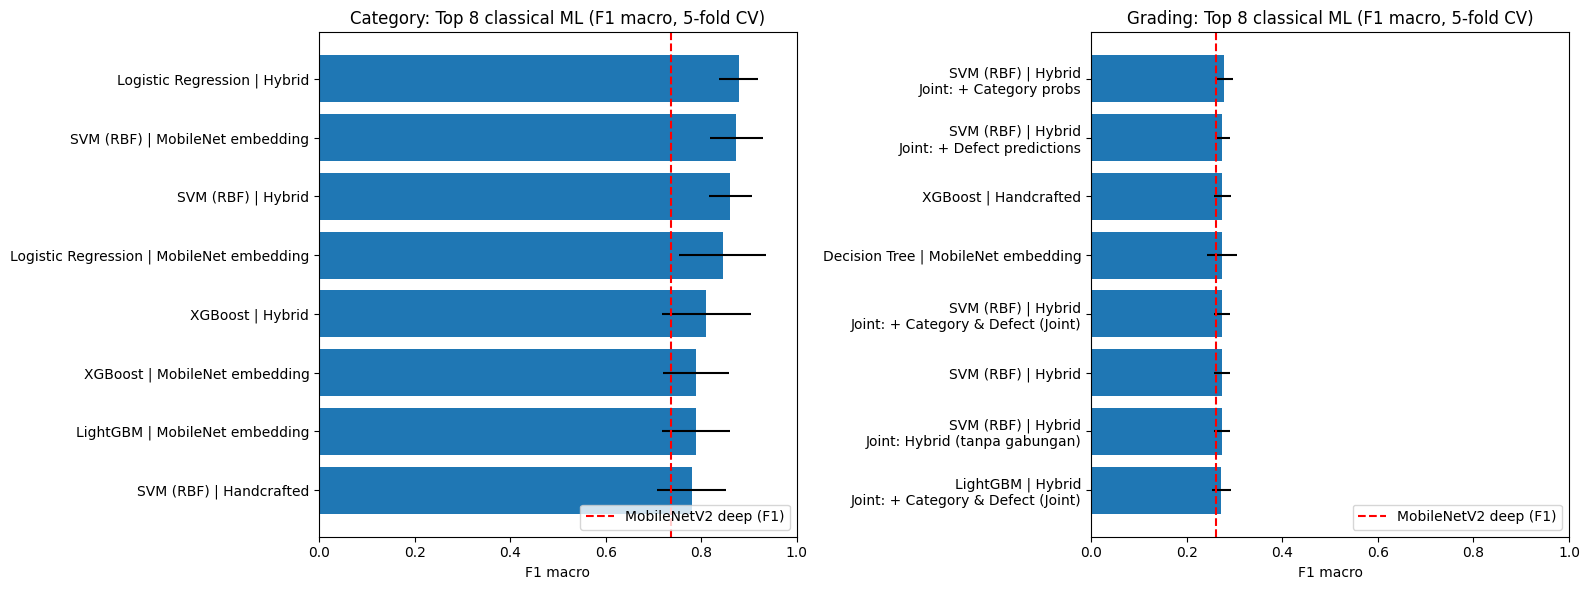

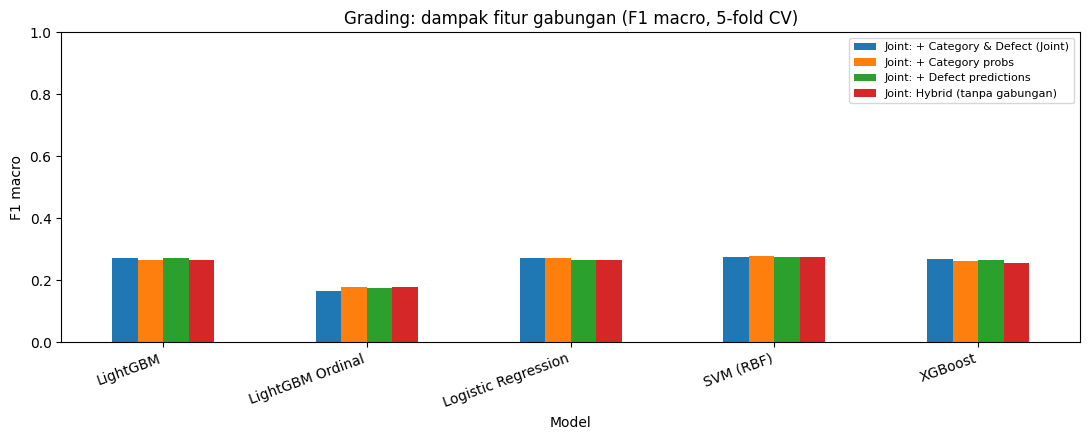

In [ ]:
def _label(r):
    return f'{r["Model"]} | {r["Features"]}' + ("" if r["Approach"] == "Baseline" else f'\n{r["Approach"]}')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, task in zip(axes, ["Category", "Grading"]):
    top = (summary[summary["Task"] == task]
           .sort_values("F1_macro_mean", ascending=False).head(8).iloc[::-1])
    ax.barh([_label(r) for _, r in top.iterrows()], top["F1_macro_mean"],
            xerr=top["F1_macro_std"].fillna(0), color="tab:blue")
    ref = deep_df[(deep_df["Task"] == task) & deep_df["Model"].str.contains("MobileNet")]
    if len(ref):
        ax.axvline(ref["F1_macro"].iloc[0], color="red", ls="--", label="MobileNetV2 deep (F1)")
        ax.legend(loc="lower right")
    ax.set_title(f"{task}: Top 8 classical ML (F1 macro, 5-fold CV)")
    ax.set_xlabel("F1 macro"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

gj = summary[(summary["Task"] == "Grading") & summary["Approach"].str.startswith("Joint")]
pv = gj.pivot_table(index="Model", columns="Approach", values="F1_macro_mean")
pv.plot(kind="bar", figsize=(11, 4.5))
plt.title("Grading: dampak fitur gabungan (F1 macro, 5-fold CV)")
plt.ylabel("F1 macro"); plt.xticks(rotation=20, ha="right"); plt.ylim(0, 1)
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

Model terbaik, confusion matrix, dan feature importance


===== Category | Logistic Regression | Hybrid | Baseline =====
CV Accuracy = 0.9592 +- 0.0104 | F1 macro = 0.8780 +- 0.0399
              precision    recall  f1-score   support

       Shirt       0.93      0.94      0.94       317
     T-Shirt       0.97      0.97      0.97       663
       Pants       0.99      0.99      0.99       203
      Jacket       0.67      0.59      0.62        17

    accuracy                           0.96      1200
   macro avg       0.89      0.87      0.88      1200
weighted avg       0.96      0.96      0.96      1200



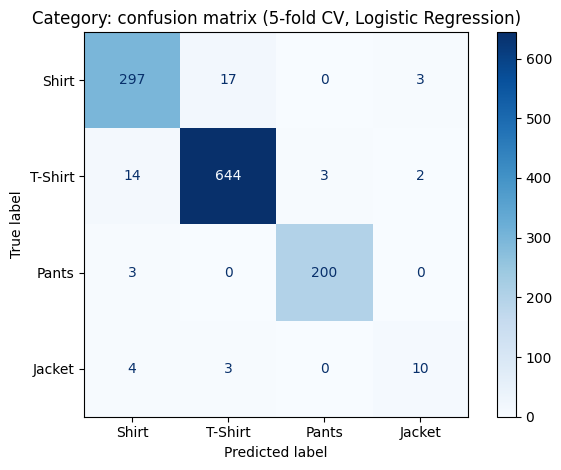


===== Grading | SVM (RBF) | Hybrid | Joint: + Category probs =====
CV Accuracy = 0.3142 +- 0.0188 | F1 macro = 0.2775 +- 0.0183
              precision    recall  f1-score   support

           A       0.35      0.35      0.35       311
           B       0.16      0.10      0.12       184
           C       0.36      0.44      0.40       414
           D       0.26      0.23      0.25       291

    accuracy                           0.31      1200
   macro avg       0.28      0.28      0.28      1200
weighted avg       0.30      0.31      0.31      1200



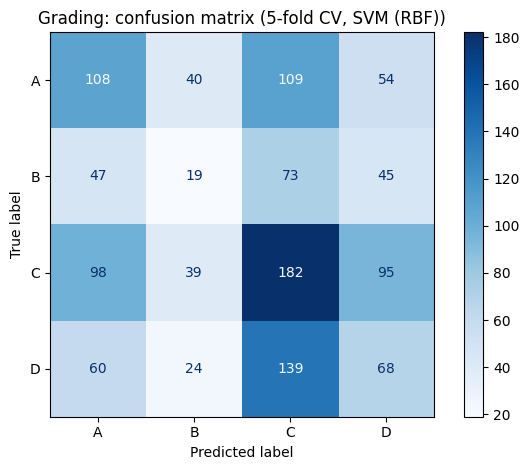

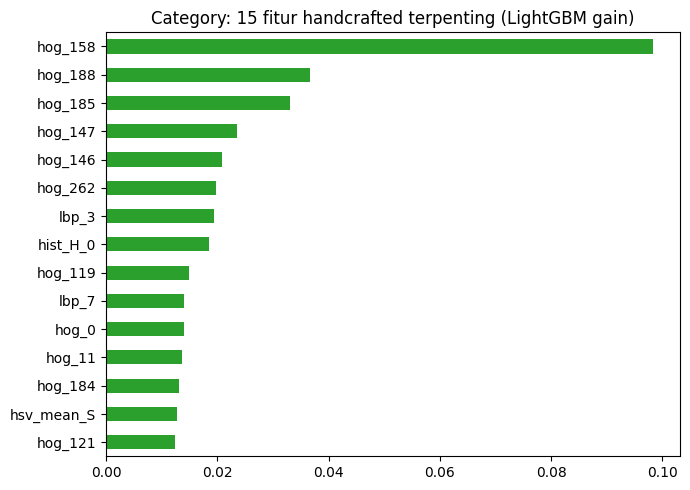

In [ ]:
best = {}
for task, classes in [("Category", CATEGORY_CLASSES), ("Grading", GRADE_CLASSES)]:
    r = summary[summary["Task"] == task].sort_values("F1_macro_mean", ascending=False).iloc[0]
    best[task] = r
    key = (task, r["Approach"], r["Features"], r["Model"])
    yt, yp = PRED_STORE[key]
    print(f"\n===== {task} | {r['Model']} | {r['Features']} | {r['Approach']} =====")
    print(f"CV Accuracy = {r['Accuracy_mean']:.4f} +- {r['Accuracy_std']:.4f} | "
          f"F1 macro = {r['F1_macro_mean']:.4f} +- {r['F1_macro_std']:.4f}")
    print(classification_report(yt, yp, target_names=classes, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(yt, yp, labels=range(len(classes))),
                           display_labels=classes).plot(cmap="Blues", values_format="d")
    plt.title(f"{task}: confusion matrix (5-fold CV, {r['Model']})")
    plt.tight_layout(); plt.show()

for task, X, y, classes in [("Category", X_hc_cat, y_category, CATEGORY_CLASSES),
                            ("Grading", X_hc_grade, y_grade, GRADE_CLASSES)]:
    lgb = make_models()["LightGBM"].fit(X, y)
    imp = pd.Series(lgb.booster_.feature_importance(importance_type="gain"), index=FEATURE_NAMES)
    imp = (imp / imp.sum()).sort_values(ascending=False).head(15).iloc[::-1]
    imp.plot(kind="barh", figsize=(7, 5), color="tab:green")
    plt.title(f"{task}: 15 fitur handcrafted terpenting (LightGBM gain)")
    plt.tight_layout(); plt.show()

Sistem akhir Category → Defect → Grading

In [38]:
def _flags(approach):
    return (False, False) if approach == "Baseline" else VARIANTS[approach.replace("Joint: ", "")]

def _assemble(fs, hc, emb):
    if fs == "Handcrafted":
        return hc
    if fs == "MobileNet embedding":
        return emb
    return np.hstack([hc, emb])

def _predict_ids(pipe, model_name, X, ymax):
    p = pipe.predict(X)
    if "Ordinal" in model_name:
        p = np.clip(np.rint(p), 0, ymax).astype(int)
    return p

def _fit(pipe, model_name, X, y):
    if model_name == "XGBoost":
        pipe.fit(X, y, clf__sample_weight=compute_sample_weight("balanced", y))
    else:
        pipe.fit(X, y)
    return pipe

bc, bg = best["Category"], best["Grading"]
EMB_C = X_emb_cat if RUN_EMBEDDINGS else None
EMB_G = X_emb_grade if RUN_EMBEDDINGS else None

# 1) model Category terbaik
final_cat = _fit(build_pipeline(bc["Model"], bc["Features"], N_HC), bc["Model"],
                 _assemble(bc["Features"], X_hc_cat, EMB_C), y_category)

# 2) model atribut cacat
use_cat, use_attr = _flags(bg["Approach"])
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
attr_models, oof_attr = [], np.zeros(A_grade.shape)
for j in range(A_grade.shape[1]):
    rf = RandomForestRegressor(n_estimators=max(100, N_EST // 2), min_samples_leaf=2,
                               max_features=0.4, n_jobs=-1, random_state=SEED)
    oof_attr[:, j] = cross_val_predict(rf, X_hc_grade, A_grade[:, j], cv=kf)
    attr_models.append(rf.fit(X_hc_grade, A_grade[:, j]))

# 3) model Grading terbaik (dengan fitur gabungan bila terpilih)
blocks = [X_hc_grade]
if use_cat:
    blocks.append(cat_proba_grade)
if use_attr:
    blocks.append(oof_attr)
hc_aug_train = np.hstack(blocks)
final_grade = _fit(build_pipeline(bg["Model"], bg["Features"], hc_aug_train.shape[1]), bg["Model"],
                   _assemble(bg["Features"], hc_aug_train, EMB_G), y_grade)

def thrifty_predict(pil_image):
    """Input: gambar PIL. Output: jenis pakaian, grade kondisi, estimasi cacat."""
    arr = image_to_array(pil_image)
    hc = extract_features(arr)[None, :]
    emb = extract_embeddings(arr[None]) if RUN_EMBEDDINGS else None

    cat_id = int(_predict_ids(final_cat, bc["Model"], _assemble(bc["Features"], hc, emb), 3)[0])
    attr_pred = np.column_stack([m.predict(hc) for m in attr_models])

    blk = [hc]
    if use_cat:
        blk.append(cat_prob_model.predict_proba(_assemble(_cat_feat_name, hc, emb)))
    if use_attr:
        blk.append(attr_pred)
    z = _assemble(bg["Features"], np.hstack(blk), emb)
    grade_id = int(_predict_ids(final_grade, bg["Model"], z, 3)[0])

    return {"category": CATEGORY_CLASSES[cat_id],
            "grade": GRADE_CLASSES[grade_id],
            "defect_estimates": {c: round(float(v), 2) for c, v in zip(ATTR_COLS, attr_pred[0])}}

print("Konfigurasi akhir")
print("  Category:", bc["Model"], "|", bc["Features"])
print("  Grading :", bg["Model"], "|", bg["Features"], "|", bg["Approach"])
print("\nContoh (gambar grading) :", thrifty_predict(df_grade.iloc[0]["image"]),
      "| label asli:", df_grade.iloc[0]["label"])
print("Contoh (gambar category):", thrifty_predict(df_category.iloc[0]["image"]),
      "| label asli:", df_category.iloc[0]["label"])

joblib.dump({"final_cat": final_cat, "final_grade": final_grade, "cat_prob_model": cat_prob_model,
             "attr_models": attr_models, "best_category": dict(bc), "best_grading": dict(bg),
             "feature_names": FEATURE_NAMES},
            "thrifty_outputs/thrifty_classical_system.joblib")
res_all.to_csv("thrifty_outputs/classical_all_results.csv", index=False)
print("\nTersimpan di thrifty_outputs/")

Konfigurasi akhir
  Category: Logistic Regression | Hybrid
  Grading : SVM (RBF) | Hybrid | Joint: + Category probs

Contoh (gambar grading) : {'category': 'Shirt', 'grade': 'D', 'defect_estimates': {'holes': 0.06, 'stains': 0.9, 'pilling': 4.84}} | label asli: D
Contoh (gambar category): {'category': 'Shirt', 'grade': 'A', 'defect_estimates': {'holes': 0.18, 'stains': 2.29, 'pilling': 4.06}} | label asli: Shirt

Tersimpan di thrifty_outputs/


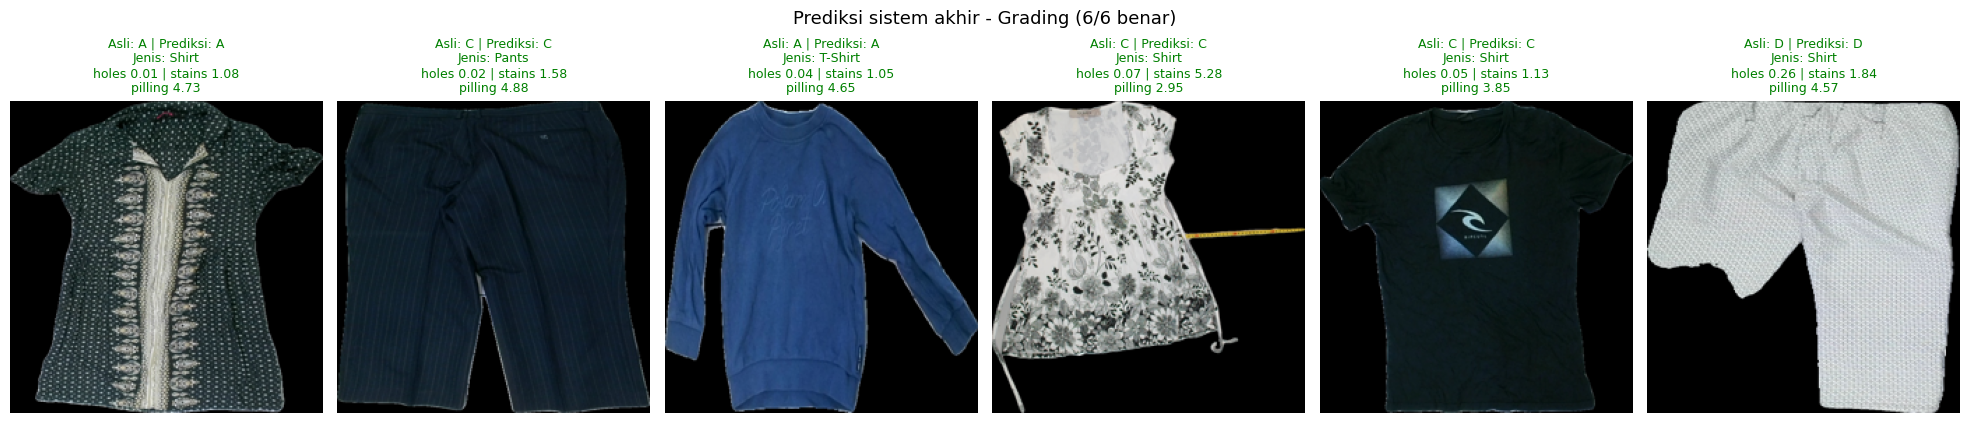

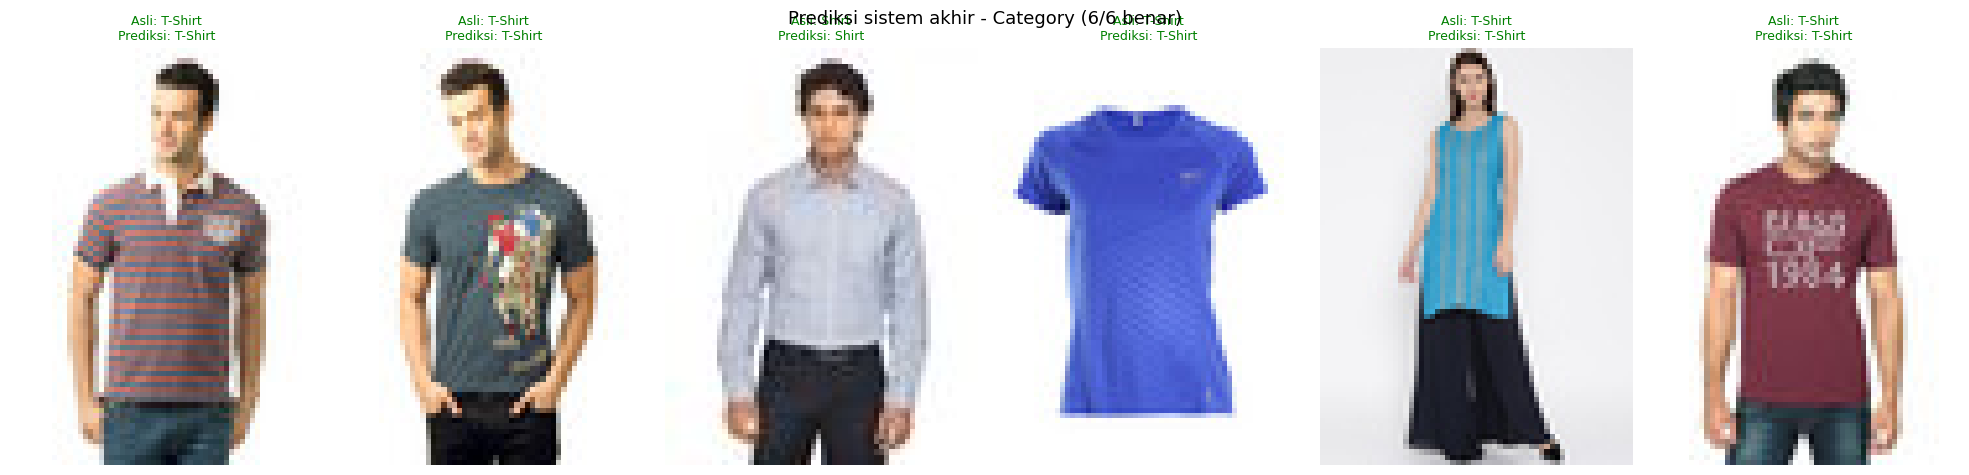

In [39]:
def show_predictions(df, task="Grading", n=6, seed=SEED):
    """Tampilkan n gambar acak + label asli vs prediksi. Hijau = benar, merah = salah."""
    idx = np.random.default_rng(seed).choice(len(df), n, replace=False)
    fig, axes = plt.subplots(1, n, figsize=(3.3 * n, 4.8))
    benar = 0
    for ax, i in zip(axes, idx):
        img = df.iloc[i]["image"]
        res = thrifty_predict(img)
        true = df.iloc[i]["label"]
        pred = res["grade"] if task == "Grading" else res["category"]
        ok = (pred == true)
        benar += ok
        ax.imshow(np.asarray(img.convert("RGB")))
        ax.axis("off")
        if task == "Grading":
            d = res["defect_estimates"]
            txt = (f"Asli: {true} | Prediksi: {pred}\n"
                   f"Jenis: {res['category']}\n"
                   f"holes {d['holes']} | stains {d['stains']}\n"
                   f"pilling {d['pilling']}")
        else:
            txt = f"Asli: {true}\nPrediksi: {pred}"
        ax.set_title(txt, fontsize=9, color="green" if ok else "red")
    plt.suptitle(f"Prediksi sistem akhir - {task} ({benar}/{n} benar)", fontsize=13)
    plt.tight_layout()
    plt.show()

show_predictions(df_grade, task="Grading", n=6)
show_predictions(df_category, task="Category", n=6)